# 04 Circuit tier (C): ngspice on a unit cell, and what is *not* SPICE

**What SPICE computes here (ngspice 42):**
1. `.ac` per-tap complex transfer functions $H_k(f)$ of lossy RLC coax lines (generic RG-58-like: $L$=250 nH/m, $C$=100 pF/m, constant series $R$ giving 32 dB/us at 100 MHz) into 50 ohm;
2. `.dc` transfer of a generic BJT differential pair, fitted with $A\tanh(v/V_{sat})+\mathrm{offset}$;
3. `.tran` of the **layer-1 unit cell** (taps as ideal VCVS into a summing node, diff pair, RC pool) on 16 test examples, compared with V.

**What is *not* SPICE:** the full 4000-example numbers, and layers 2-3 (dilations 4 and 16, much longer lines), come from the **circuit-calibrated behavioural model**: a closed-form RLC line fitted to the SPICE $H_k(f)$ (max $|\Delta H|$ about $10^{-13}$) and extrapolated to the longer taps, plus the fitted tanh. Nothing about layers 2-3 is verified in SPICE.

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")
import tempfile
from pathlib import Path
from dlnn.tiers import circuit, virtual
model = run.model
P = run.params
ly0 = model.layers[0]
r_nom = circuit.r_from_loss(32.0)
print("ngspice:", circuit.ngspice_path(), "| version", circuit.ngspice_version())
print("extraction source recorded in the run:", P["source"], "| tool", P["tool"])

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000
ngspice: /usr/bin/ngspice | version 42
extraction source recorded in the run: ngspice | tool {'name': 'ngspice', 'version': '42'}


## The netlists

In [2]:
def head(txt, n=22):
    ls = txt.splitlines(); print("\n".join(ls[:n]) + (f"\n... ({len(ls) - n} more lines)" if len(ls) > n else ""))
print("=== hw/spice/coax_rg58.lib (generic lossy line, LTRA) ==="); head((nb.ROOT / "hw/spice/coax_rg58.lib").read_text(), 24)
print("\n=== diff-pair .dc netlist (generated by circuit.netlist_dc) ==="); head(circuit.netlist_dc(), 20)

=== hw/spice/coax_rg58.lib (generic lossy line, LTRA) ===
* ----------------------------------------------------------------------------
* coax_rg58.lib : GENERIC lossy RLC coax model (ngspice LTRA) for the DLNN circuit tier.
*
* NOT a vendor model and NOT a measurement of any real cable.
*   L = 250 nH/m, C = 100 pF/m  -> Z0 = 50 ohm, v_p = 1/sqrt(LC) = 2.00e8 m/s (20.0 cm/ns;
*   the real RG-58 figure of 19.8 cm/ns is 1 % lower, so line lengths here are cut to give
*   EXACTLY k*d*Ts of delay).
*   R is a CONSTANT series resistance (ohm/m) chosen so that the matched-line attenuation is
*   32 dB/us at 100 MHz:  alpha = R/(2 Z0)  ->  R = 2 Z0 * (32/8.686) / (v_p*1e-6) = 1.8421 ohm/m.
*   Deviations from real RG-58 that this model deliberately has (also listed in the tier
*   fidelity.omits): no sqrt(f) skin-effect loss and no skin-effect dispersion (so the loss is
*   too high at low frequency: DC loss of a 14 m line is -3.6 dB here against ~0.1 dB for real
*   cable), G = 0 (ngspice 

In [3]:
print("=== tap-line .ac netlist (K=8 taps, d=1) ==="); head(circuit.netlist_ac(8, 1, r_nom), 24)
cell = (run.dir / "spice" / "unit_cell_ex00.cir")
print("=== layer-1 unit-cell .tran netlist, example 0 (from the run). Shown: header, supplies, 2 of the tap lines, ALL elements of output 0; the PWL input data and outputs 1-7 are elided ===")
import re
txt = cell.read_text().splitlines()
pick = [l for l in txt if l.startswith(("*", ".")) or re.match(r"^(Vcc|Vcm|Xline_0_[12] |Rterm_0_[12] |Etap_0_|Epre0 |Vb0 |Ep0 |En0 |Xdp0 |Eout0 |Rpool0 |Cpool0 )", l)]
print(f"[{len(txt)} lines in the file]")
print("\n".join(l[:150] for l in pick))
print("Vin0 in0 0 PWL(0 0 ... 128 symbols, 1 ns edges ...)   <- input line I as a PWL source (elided)")

=== tap-line .ac netlist (K=8 taps, d=1) ===
* DLNN tap-line AC extraction, K=8, d=1
* GENERIC textbook models only: RLC coax (L=250 nH/m, C=100 pF/m, constant R) and a generic NPN diff pair; not vendor models, no measured hardware.
* GENERATED by dlnn.tiers.circuit - do not hand-edit
.param coax_r=1.84206807
.include /home/user/dlnn/hw/spice/coax_rg58.lib
.include /home/user/dlnn/hw/spice/diffpair.lib
V1 in 0 DC 0 AC 1
Xline1 in tap1 coax_rg58 len=2
Rterm1 tap1 0 50
Xline2 in tap2 coax_rg58 len=4
Rterm2 tap2 0 50
Xline3 in tap3 coax_rg58 len=6
Rterm3 tap3 0 50
Xline4 in tap4 coax_rg58 len=8
Rterm4 tap4 0 50
Xline5 in tap5 coax_rg58 len=10
Rterm5 tap5 0 50
Xline6 in tap6 coax_rg58 len=12
Rterm6 tap6 0 50
Xline7 in tap7 coax_rg58 len=14
Rterm7 tap7 0 50
.ac lin 1025 1 500000000
.save v(tap1) v(tap2) v(tap3) v(tap4) v(tap5) v(tap6) v(tap7)
.end
=== layer-1 unit-cell .tran netlist, example 0 (from the run). Shown: header, supplies, 2 of the tap lines, ALL elements of output 0; the PWL inp

## Live `.dc`: the diff pair is a tanh

ngspice .dc: 0.2 s | fit A = 0.9904 V, V_sat = 52.02 mV (2*V_T design 51.8 mV), R^2 = 0.99999997, rms residual 0.158 mV
fitted V_T = 26.01 mV vs ngspice thermal voltage at 27 C = 25.86 mV
stored extraction (run): V_sat 52.02 mV, R^2 0.99999997  -> same


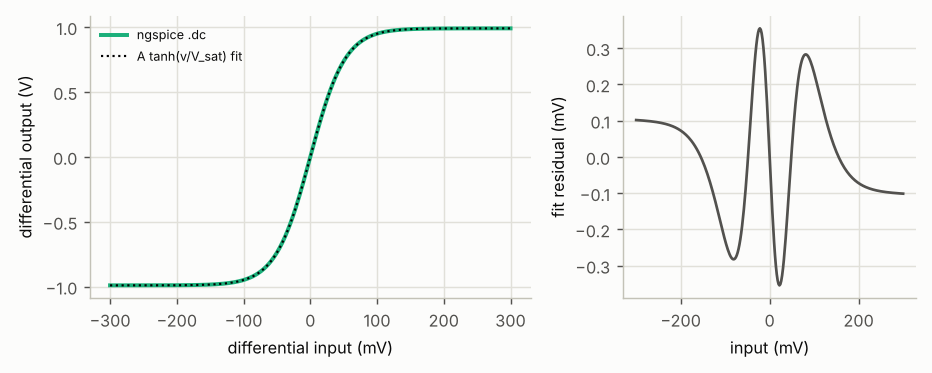

In [4]:
t0 = time.time()
with tempfile.TemporaryDirectory() as td:
    dc = circuit.extract_dc(Path(td), True)
v, yv, ft = dc["v"], dc["y"], dc["fit"]
print(f"ngspice .dc: {time.time() - t0:.1f} s | fit A = {ft['A_v']:.4f} V, V_sat = {1e3 * ft['vsat_v']:.2f} mV (2*V_T design 51.8 mV), R^2 = {ft['r2']:.8f}, rms residual {1e3 * ft['rms_resid_v']:.3f} mV")
print(f"fitted V_T = {1e3 * ft['v_t_fitted_v']:.2f} mV vs ngspice thermal voltage at 27 C = {1e3 * ft['v_t_ngspice_27c_v']:.2f} mV")
print(f"stored extraction (run): V_sat {1e3 * P['diffpair']['vsat_v']:.2f} mV, R^2 {P['diffpair']['r2']:.8f}  -> same")
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.9), gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].plot(1e3 * v, yv, color=TIER_COL["light"]["C"], lw=2.2, label="ngspice .dc")
axs[0].plot(1e3 * v, ft["A_v"] * np.tanh(v / ft["vsat_v"]) + ft["offset_v"], "k:", lw=1.2, label="A tanh(v/V_sat) fit")
axs[0].set_xlabel("differential input (mV)"); axs[0].set_ylabel("differential output (V)"); axs[0].legend(fontsize=7)
axs[1].plot(1e3 * v, 1e3 * (yv - (ft["A_v"] * np.tanh(v / ft["vsat_v"]) + ft["offset_v"])), color=INK["light"]["sec"])
axs[1].set_xlabel("input (mV)"); axs[1].set_ylabel("fit residual (mV)")
fig.tight_layout(); nb.show_fig(fig)

## Live `.ac`: per-tap transfer functions $H_k(f)$ and the closed-form fit

ngspice .ac: 0.0 s, 1025 points up to 500 MHz
closed-form RLC fit: R = 1.8421 ohm/m, L = 250.0 nH/m, C = 100.0 pF/m -> loss 32.00 dB/us @100 MHz, max |dH| = 1.3e-13


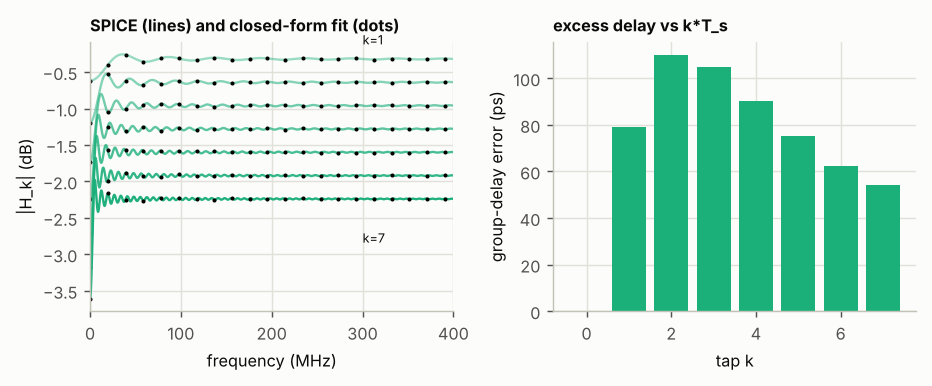

| k | length (m) | DC gain (dB) | gain @100 MHz (dB) | delay error (ps) |
|---|---|---|---|---|
| 0 | 0.00 | 0.00 | 0.00 | 0 |
| 1 | 2.00 | -0.62 | -0.32 | 79 |
| 2 | 4.00 | -1.19 | -0.64 | 110 |
| 3 | 6.00 | -1.73 | -0.96 | 105 |
| 4 | 8.00 | -2.24 | -1.28 | 90 |
| 5 | 10.00 | -2.72 | -1.60 | 75 |
| 6 | 12.00 | -3.18 | -1.92 | 63 |
| 7 | 14.00 | -3.61 | -2.24 | 54 |

*The LTRA line has constant series R and no shunt G, so the low-frequency loss is overstated (DC about -3.6 dB vs -2.2 dB at 100 MHz for the longest layer-1 tap): a known limit of this SPICE line model, stated in the tier's `fidelity.omits`.*

In [5]:
t0 = time.time()
with tempfile.TemporaryDirectory() as td:
    ac = circuit.extract_ac(Path(td), 8, 1, r_nom, True)
f, H, fit = ac["freq_hz"], ac["H"], ac["fit"]
print(f"ngspice .ac: {time.time() - t0:.1f} s, {len(f)} points up to {f[-1] / 1e6:.0f} MHz")
print(f"closed-form RLC fit: R = {fit['R_ohm_per_m']:.4f} ohm/m, L = {1e9 * fit['L_h_per_m']:.1f} nH/m, C = {1e12 * fit['C_f_per_m']:.1f} pF/m -> loss {fit['loss_db_per_us_100mhz']:.2f} dB/us @100 MHz, max |dH| = {fit['fit_max_abs_err']:.1e}")
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
for k in range(1, 8):
    axs[0].plot(f / 1e6, 20 * np.log10(np.abs(H[k])), lw=1.3, color=TIER_COL["light"]["C"], alpha=0.35 + 0.09 * k)
    fitH = circuit.line_H(f, circuit.tap_lengths(8, 1)[k], fit["R_ohm_per_m"], fit["L_h_per_m"], fit["C_f_per_m"])
    axs[0].plot(f[::40] / 1e6, 20 * np.log10(np.abs(fitH[::40])), "k.", ms=2.5)
axs[0].text(300, 20 * np.log10(abs(H[7, np.argmin(abs(f - 300e6))])) - 0.6, "k=7", fontsize=7); axs[0].text(300, 20 * np.log10(abs(H[1, np.argmin(abs(f - 300e6))])) + 0.2, "k=1", fontsize=7)
axs[0].set_xlim(0, 400); axs[0].set_xlabel("frequency (MHz)"); axs[0].set_ylabel("|H_k| (dB)"); axs[0].set_title("SPICE (lines) and closed-form fit (dots)", fontsize=9)
dly = np.array([t["delay_error_s"] for t in ac["taps"]]) * 1e12
axs[1].bar(range(8), dly, color=TIER_COL["light"]["C"]); axs[1].set_xlabel("tap k"); axs[1].set_ylabel("group-delay error (ps)"); axs[1].set_title("excess delay vs k*T_s", fontsize=9)
fig.tight_layout(); nb.show_fig(fig)
rows = ["| k | length (m) | DC gain (dB) | gain @100 MHz (dB) | delay error (ps) |", "|---|---|---|---|---|"]
for t in ac["taps"]:
    rows.append(f"| {t['k']} | {t['length_m']:.2f} | {t['dc_gain_db']:.2f} | {t['gain_100mhz_db']:.2f} | {1e12 * t['delay_error_s']:.0f} |")
nb.md("\n".join(rows))
nb.md("*The LTRA line has constant series R and no shunt G, so the low-frequency loss is overstated (DC about -3.6 dB vs -2.2 dB at 100 MHz for the longest layer-1 tap): a known limit of this SPICE line model, stated in the tier's `fidelity.omits`.*")

## Live `.tran`: the layer-1 unit cell on a few examples, SPICE vs V vs calibrated model

3 examples x 8 output lines in ngspice: 5 s (tran: 3333 time points each)
layer-1 NMSE SPICE vs V (variance-normalised): 0.0238 | calibrated model vs SPICE: 2.58e-07


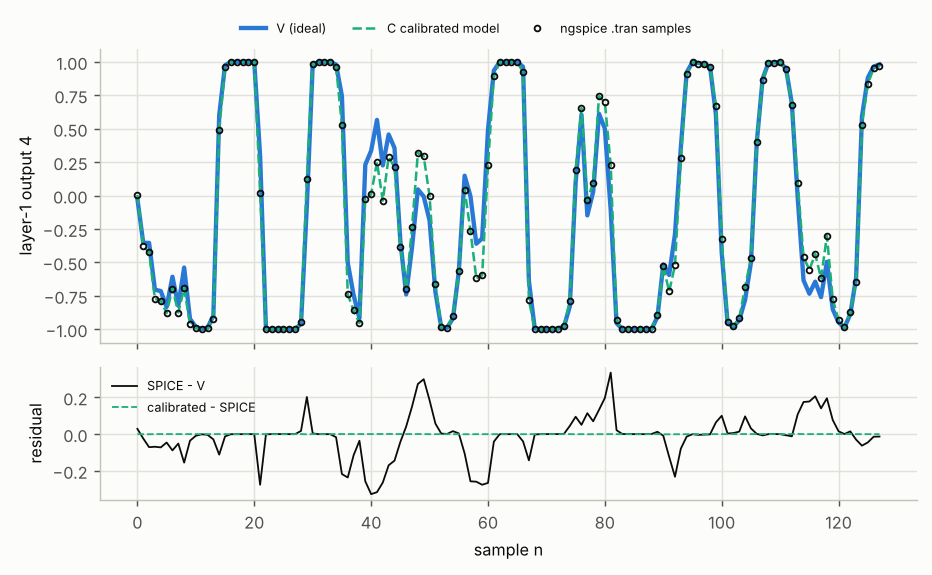


Stored (run, 16 examples x 8 lines): NMSE vs V = 0.0220 (no gain trim: 0.0267); calibrated vs SPICE = 2.7e-07; SPICE wall 20 s


In [6]:
from dlnn.model.npz import Layer
ds_min = {"x_test": run.x_test, "task": "classification"}
fitp = P["line"]["fit"]; ampp = P["amp"]
line = circuit.LineModel(fitp["R_ohm_per_m"], fitp["L_h_per_m"], fitp["C_f_per_m"])
amp = circuit.AmpModel(ampp["vsat_scale"], ampp["gain_scale"], ampp["offset_rel"])
trim = float(P["loss_comp_gain_trim_per_layer"][0])
t0 = time.time()
with tempfile.TemporaryDirectory() as td:
    tran, y_c, y_v, ex = circuit.run_unit_cell(Path(td), model, ds_min, {"c_n_examples": 3, "c_outputs": 8, "c_workers": 2}, r_nom, trim, line, amp)
print(f"3 examples x 8 output lines in ngspice: {time.time() - t0:.0f} s (tran: {tran['tran_timepoints_per_run']} time points each)")
print(f"layer-1 NMSE SPICE vs V (variance-normalised): {tran['nmse']:.4f} | calibrated model vs SPICE: {tran['nmse_calibrated_model_vs_spice']:.2e}")
cal = circuit.calibrated_forward(model, ex, line, amp, comp="layer", trims=[trim, 1, 1])["layers"][0][:, :8]
o = 4
fig, axs = plt.subplots(2, 1, figsize=(7.2, 4.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
e = 0
axs[0].plot(y_v[e, o], color=TIER_COL["light"]["V"], lw=2.4, label="V (ideal)")
axs[0].plot(cal[e, o], color=TIER_COL["light"]["C"], ls="--", lw=1.4, label="C calibrated model")
axs[0].plot(y_c[e, o], "o", mfc="none", mec=INK["light"]["text"], ms=3.2, label="ngspice .tran samples")
axs[0].set_ylabel(f"layer-1 output {o}"); h_, l_ = axs[0].get_legend_handles_labels(); fig.legend(h_, l_, fontsize=7, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.04))
axs[1].plot(y_c[e, o] - y_v[e, o], color=INK["light"]["text"], lw=1.0, label="SPICE - V"); axs[1].plot(cal[e, o] - y_c[e, o], color=TIER_COL["light"]["C"], lw=1.0, ls="--", label="calibrated - SPICE")
axs[1].set_xlabel("sample n"); axs[1].set_ylabel("residual"); axs[1].legend(fontsize=7)
fig.tight_layout(); nb.show_fig(fig)
u16 = P["unit_cell_tran"]
print(f"\nStored (run, 16 examples x 8 lines): NMSE vs V = {u16['nmse']:.4f} (no gain trim: {u16['no_trim']['nmse']:.4f}); calibrated vs SPICE = {u16['nmse_calibrated_model_vs_spice']:.1e}; SPICE wall {u16['spice_wall_s']:.0f} s")

### What is SPICE and what is calibrated (for this run)

| quantity | where it comes from |
|---|---|
| per-tap $H_k(f)$, $k\le7$, $d=1$ | **ngspice `.ac`** |
| diff-pair tanh ($V_{sat}$, gain, offset, $R^2$) | **ngspice `.dc`** + fit |
| layer-1 activations on 16 examples | **ngspice `.tran`** (unit cell, 8 outputs) |
| layer-1 activations, the other 3984 examples | calibrated behavioural model (reproduces SPICE to NMSE $\approx 10^{-7}$ on the 16) |
| layers 2-3 (all examples) | calibrated model, **line fit extrapolated to 4x and 16x longer taps. Not SPICE.** |
| accuracy / agreement / KL / sweeps of tier C | calibrated model |
| RC pool | SPICE uses a leaky average ($\tau=NT_s$); the model trains with a uniform mean (NMSE 0.22 between them): not matched |

## The loss sweep, and the choice of loss compensation (full test set, calibrated model, not SPICE)

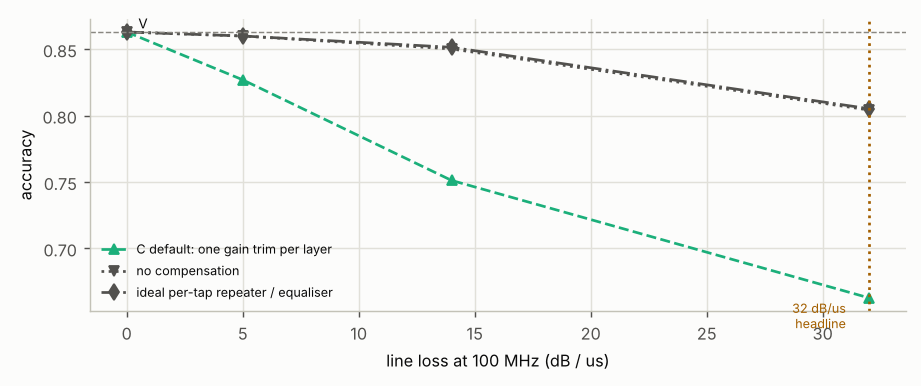

| compensation (at 32 dB/us) | accuracy | top-1 agreement with V | mean KL |
|---|---|---|---|
| one ideal gain trim per layer (tier default) | 0.663 | 0.662 | 1.055 |
| none | 0.804 | 0.871 | 0.157 |
| tap | 0.805 | 0.846 | 0.161 |

**Reading the gap.** At 0 dB/us the calibrated model reproduces V (0.863). The C headline of 0.663 is the **32 dB/us operating point with the tier's default loss compensation** (a single trim per layer). The diagnostics in `params/circuit_diagnostics.json` show the compensation choice matters as well: with no compensation or an ideal per-tap equaliser the same loss gives about 0.80. Most of C's 20-point gap to V is therefore the default per-layer gain trim (0.663 vs 0.804 with none), not line loss (about 6 points); in layer 3 the trim of 2.85 puts 72.8 % of the activations into tanh saturation against 49.9 % in V (`docs/circuit_extraction.md`, measured with `scripts/saturation_check.py`). Per-tap repeaters are what the plan says the dilation-16 layer needs, and the line loss alone makes the operating point unbuildable without them; this simulation does not include them in the headline.

In [7]:
diag = json.loads((run.dir / "params" / "circuit_diagnostics.json").read_text())
swC = cmp["sweeps"]["loss_db_per_us"]["C"]
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.plot(swC["values"], swC["accuracy"], "^--", color=TIER_COL["light"]["C"], label=f"C default: one gain trim per layer")
sty = {"none": ("v", ":"), "tap": ("d", "-.")}
for mode, v in diag["modes"].items():
    s = v["loss_sweep"]; ax.plot(s["values"], s["accuracy"], marker=sty[mode][0], ls=sty[mode][1], color=INK["light"]["sec"], label={"none": "no compensation", "tap": "ideal per-tap repeater / equaliser"}[mode])
ax.axhline(cmp["metric_matrix"]["accuracy"]["V"], color=INK["light"]["muted"], ls="--", lw=0.8); ax.text(0.5, cmp["metric_matrix"]["accuracy"]["V"] + 0.003, "V", fontsize=7.5)
ax.axvline(32, color=INK["light"]["warn"], ls=":"); ax.text(31, 0.64, "32 dB/us\nheadline", fontsize=7, color=INK["light"]["warn"], ha="right")
ax.set_xlabel("line loss at 100 MHz (dB / us)"); ax.set_ylabel("accuracy"); ax.legend(fontsize=7, loc="lower left"); fig.tight_layout(); nb.show_fig(fig)
rows = ["| compensation (at 32 dB/us) | accuracy | top-1 agreement with V | mean KL |", "|---|---|---|---|",
        f"| one ideal gain trim per layer (tier default) | {cmp['metric_matrix']['accuracy']['C']:.3f} | {cmp['metric_matrix']['top1_agreement_vs_virtual']['C']:.3f} | {cmp['metric_matrix']['mean_kl_virtual_vs_tier']['C']:.3f} |"]
for mode, v in diag["modes"].items():
    m = v["metrics_at_fitted_loss"]; rows.append(f"| {mode} | {m['accuracy']:.3f} | {m['top1_agreement_vs_virtual']:.3f} | {m['mean_kl_virtual_vs_tier']:.3f} |")
nb.md("\n".join(rows))
nb.md("**Reading the gap.** At 0 dB/us the calibrated model reproduces V (0.863). The C headline of 0.663 is the **32 dB/us operating point with the tier's default loss compensation** (a single trim per layer). The diagnostics in `params/circuit_diagnostics.json` show the compensation choice matters as well: with no compensation or an ideal per-tap equaliser the same loss gives about 0.80. Most of C's 20-point gap to V is therefore the default per-layer gain trim (0.663 vs 0.804 with none), not line loss (about 6 points); in layer 3 the trim of 2.85 puts 72.8 % of the activations into tanh saturation against 49.9 % in V (`docs/circuit_extraction.md`, measured with `scripts/saturation_check.py`). Per-tap repeaters are what the plan says the dilation-16 layer needs, and the line loss alone makes the operating point unbuildable without them; this simulation does not include them in the headline.")

## The same example through all tiers (figure 2) and the C vs R channels (figure 3)

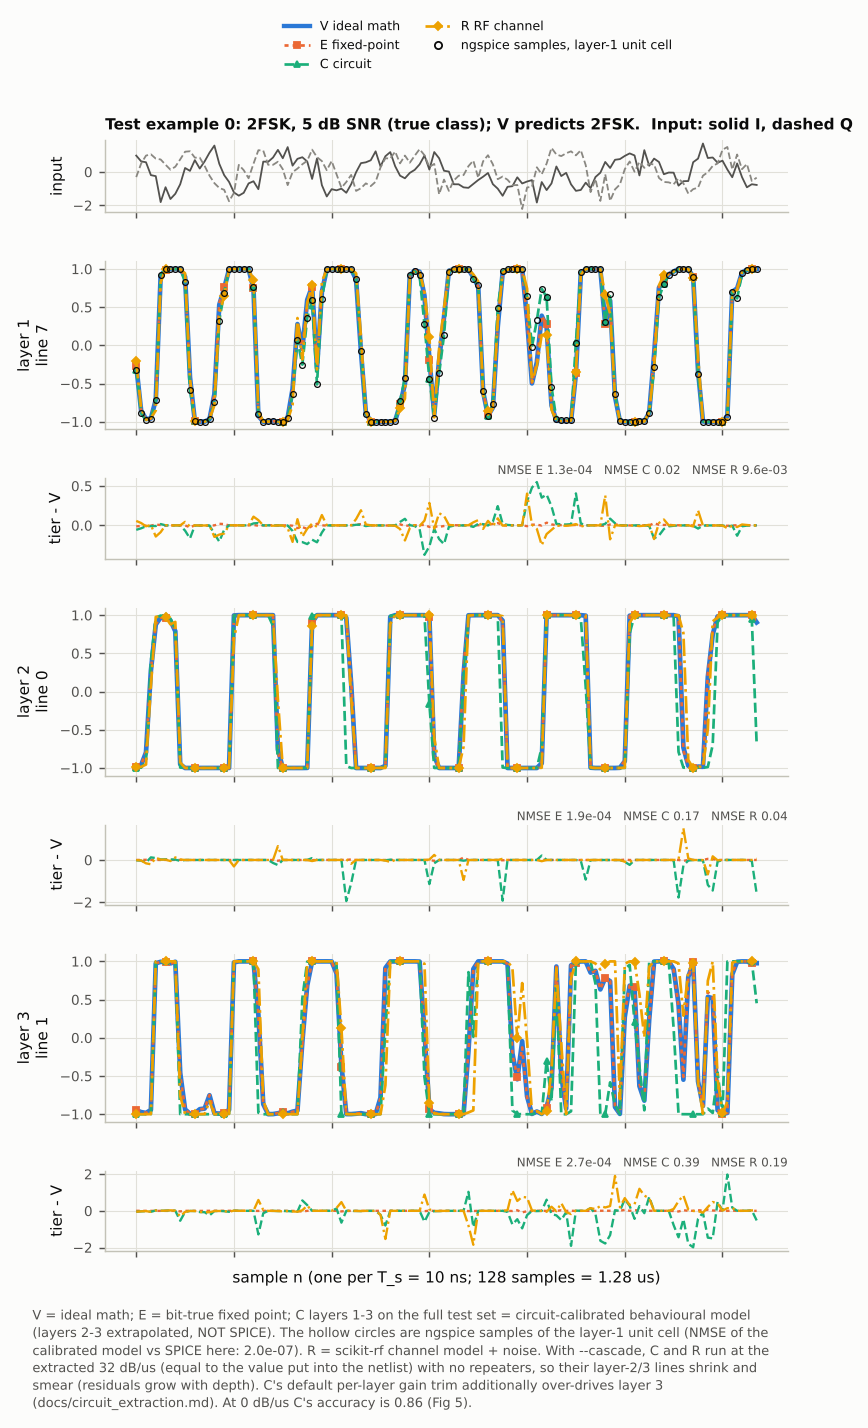

In [8]:
nb.show('fig2_traces', run)

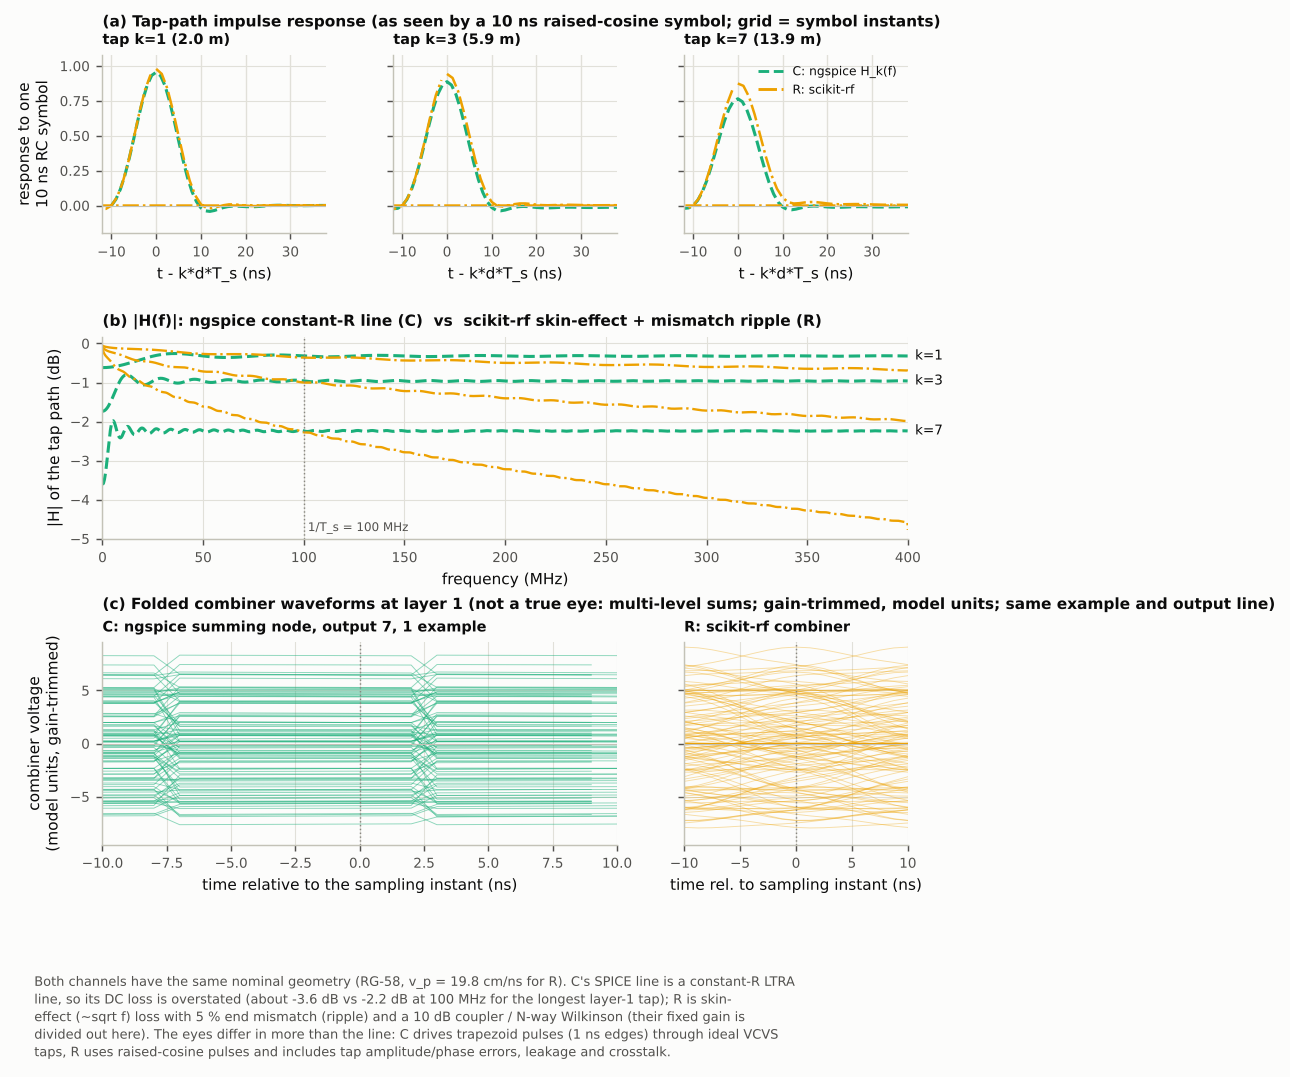

In [9]:
nb.show('fig3_channel', run)